# Template

In [256]:

from matplotlib import pyplot as plt
import cv2
import numpy as np

In [257]:
rgb = cv2.imread('calib/3d/img_0001.jpg')

In [258]:
rgb.shape

(480, 752, 3)

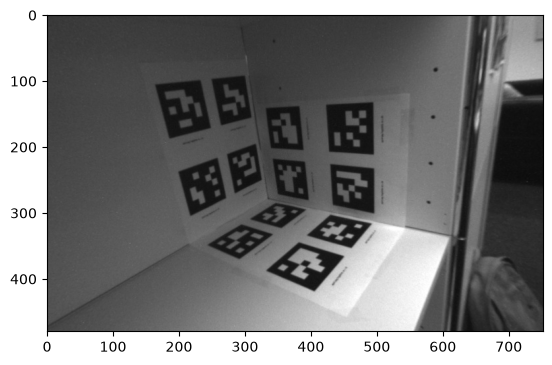

In [259]:
plt.imshow(rgb)

In [260]:
det_corners = np.loadtxt('calib/3d/detected_corners.txt')

In [261]:
det_corners

array([[186.5, 187.5, 264.5, ..., 280.5, 496.5, 300.5],
       [186.5, 186.5, 264.5, ..., 279.5, 496.5, 300.5],
       [187.5, 186.5, 265.5, ..., 279.5, 496.5, 300.5],
       ...,
       [220.5, 216.5, 293.5, ..., 306.5, 547.5, 319.5],
       [214.5, 226.5, 289.5, ..., 313.5, 542.5, 327.5],
       [208.5, 236.5, 283.5, ..., 322.5, 537.5, 336.5]], shape=(210, 24))

In [262]:
X = det_corners[:,0::2]
Y = det_corners[:,1::2]

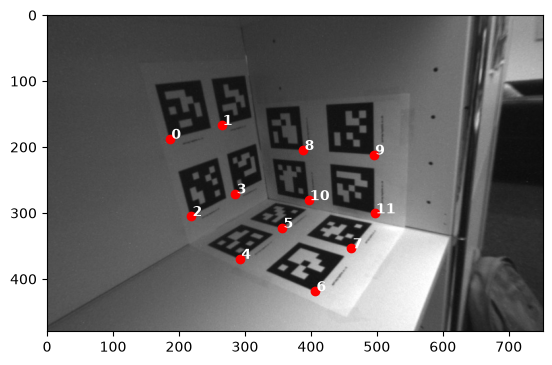

In [263]:
plt.imshow(rgb)
plt.plot(X[0,:], Y[0,:],'ro')
# Etiquetar cada punto con el número de su fila/índice
for i in range(len(X[0, :])):
    # (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
    plt.text(X[0, i] + 2, Y[0, i], str(i), color='white', fontsize=10, weight='bold')

plt.show()



In [264]:
real_corners = np.loadtxt('calib/3d/p_W_corners.txt',delimiter=',')

In [265]:
real_corners


array([[  0.  ,   8.  ,   0.  ],
       [ 10.4 ,   8.  ,   0.  ],
       [  0.  ,  21.5 ,   0.  ],
       [ 10.4 ,  21.5 ,   0.  ],
       [  0.  ,  26.6 , -10.95],
       [ 10.4 ,  26.6 , -10.95],
       [  0.  ,  26.6 , -24.45],
       [ 10.4 ,  26.6 , -24.45],
       [ 19.4 ,  14.6 , -10.95],
       [ 19.4 ,  14.6 , -24.45],
       [ 19.4 ,  25.  , -10.95],
       [ 19.4 ,  25.  , -24.45]])

In [266]:
Xw, Yw, Zw = real_corners[:,0], real_corners[:,1],real_corners[:,2]
Xw

array([ 0. , 10.4,  0. , 10.4,  0. , 10.4,  0. , 10.4, 19.4, 19.4, 19.4,
       19.4])

In [267]:
'''
import plotly.express as px
import pandas as pd
import plotly.io as pio
pio.renderers.default = 'notebook'  # O prueba con 'notebook'

df = pd.DataFrame({'x': Xw,'y': Zw,'z': -Yw})

# Crear el gráfico de dispersión 3D interactivo
fig = px.scatter_3d(df, x='x', y='y', z='z', title='Gráfico 3D Interactivo')
# Mostrar el gráfico (se abrirá en tu navegador o notebook)
fig.show()
'''

"\nimport plotly.express as px\nimport pandas as pd\nimport plotly.io as pio\npio.renderers.default = 'notebook'  # O prueba con 'notebook'\n\ndf = pd.DataFrame({'x': Xw,'y': Zw,'z': -Yw})\n\n# Crear el gráfico de dispersión 3D interactivo\nfig = px.scatter_3d(df, x='x', y='y', z='z', title='Gráfico 3D Interactivo')\n# Mostrar el gráfico (se abrirá en tu navegador o notebook)\nfig.show()\n"

# Módulo ALC

In [268]:

#Producto Matricial
def multiplicarMatrices(A,B):
    filasA,columnasA = A.shape
    filasB,columnasB = B.shape
    if columnasA != filasB:
        return None
    M = np.zeros((filasA,columnasB))
    for i in range(filasA):
        for j in range(columnasB):
            suma = 0
            for k in range(filasB):
                suma += A[i][k] * B[k][j]
            M[i][j] = suma
    return M

def calculaLU(A):
    if A is None:
        return None,None,0

    cant_op = 0
    m=A.shape[0]
    n=A.shape[1]
    Ac = A.copy()
    L = np.eye(n)

    if m!=n or A is None:
        return None,None,0
    cant_op = 0
    for i in range(n):
        if Ac[i,i] == 0:
          return None, None, 0
        for j in range(i+1,n):
            cant_op += 1+ 2*(n-i-1)
            pivot = Ac[j,i] / Ac[i,i]
            L[j,i] = pivot
            Ac[j] = Ac[j] - pivot*Ac[i]
    U = Ac

    return L, U, cant_op

def calculaLDV(A):
  n = A.shape[0]
  D = np.eye(n)
  D_inv = np.eye(n)
  L,U,cant = calculaLU(A)
  if L is None:
    return None, None, None
  for i in range(n):
    D[i,i] = U[i,i]
    D_inv[i,i] = 1/U[i,i]

  # Arriba calculo la inversa directamente, Me quede V = D^-1@V
  V = multiplicarMatrices(D_inv, U)
  return L,D,V

def norma(x,p):
    max = 0
    res = 0
    if x.ndim ==1:
      if p == 'inf':
        for i in range(len(x)):
          if max < abs(x[i]):
            max = abs(x[i])
        return max

      for i in range(len(x)):
          res+= abs(x[i])**p
      return res**(1/p)

    n = x.shape[1]
    resultado = np.zeros(n)

    for j in range(n):
      resultado[j] = norma(x[:,j],p)
    return resultado

def calcularAx(A, v):
    print(A)
    w = np.zeros((A.shape[0]))
    for i in range(A.shape[0]):
        row = v * A[i]
        sum_row = 0
        for elem in row:
            sum_row += elem
        w[i] = sum_row
    return w

def f(A, v):
    w = calcularAx(A, v)
    norm = norma(w,2)
    if norm > 0:
        w = w/norm
    return w

def f_k(A, v, k):
    for i in range(k):
        v = f(A, v)
    return v


def prodVect(v,w):
  n = len(v)
  suma = 0
  for i in range(n):
    suma += v[i]*w[i]
  return suma

def metpot2k(A,tol=1e-15,K=1000):
  fil,col = A.shape
  v = np.random.rand(fil)
  v_p = f_k(A,v,2)
  e = v_p.T @ v
  k = 0
  while abs(e - 1) > tol and k < K:
    v = v_p
    v_p = f_k(A,v,2)
    e = prodVect(v_p,v)
    k += 1
  lamb = prodVect(v_p.T, calcularAx(A,v_p))
  eps = e - 1
  return v, lamb, k, eps

def diagRH(A,tol=1e-15,K=1000):
  fil,col = A.shape
  v1, lamb1, _, _ = metpot2k(A,tol,K)
  I = np.eye(fil)
  u = (I[:,0]-v1).reshape(-1, 1)
  H_v1 = I-2*(u@u.T)/(u.T@u)
  if fil == 2:
    S = H_v1
    D = H_v1 @ A @ H_v1.T
    return S,D
  else:
    B = H_v1 @ A @ H_v1.T
    A_2 = B[1:fil,1:fil]
    S_2, D_2 =  diagRH(A_2,tol,K)
    D = np.zeros((fil,fil))
    D[0,0] = lamb1
    D[1:,1:] = D_2
    S = np.eye(fil)
    S[1:,1:] = S_2
    S = H_v1 @ S
    return S, D



def svd_reducida(A, k="max", tol=1e-15):

    fil, col = A.shape
    traspuesta = fil < col

    if traspuesta:
        A = A.T

    # Diagonalizar AtA
    At_A = multiplicarMatrices(A.T, A)

    S, D = diagRH(At_A, tol)
    V = S

    autoval = np.diag(D)

    # Ordenar autovalores de mayor a menor
    idx = sorted(range(len(autoval)),
                 key=lambda i: autoval[i],
                 reverse=True)

    autoval = autoval[idx]
    V = V[:, idx]

    # Eliminar autovalores nulos
    mask = autoval > tol

    autoval = autoval[mask]
    V = V[:, mask]

    # Limitar cantidad de valores singulares
    if k == "max":
        k = len(autoval)

    k = min(k, len(autoval))

    autoval = autoval[:k]
    V = V[:, :k]

    # Calcular valores singulares
    hatSig = autoval**(0.5)

    # Calcular U
    B = multiplicarMatrices(A, V)
    
    U_hat = np.zeros(B.shape)
    for j in range(k):
        U_hat[:, j] = B[:, j] / norma(B[:,j],2)


    # Deshacer transposición
    if traspuesta:
        U_hat, V = V, U_hat

    return U_hat, hatSig, V


def QR_con_GS(A):
  fil, col = A.shape
  if col != fil:
    return None
  Q = np.zeros((fil,col))
  R = np.zeros((fil,col))
  norm_a1 = norma(A[:,0],2)
  Q[:,0] = A[:,0]/norm_a1
  R[0,0] = norm_a1
  for j in range(1,fil):
    Q[:,j] = A[:,j]
    for k in range(j):
      R[k,j] = Q[:,k].T@Q[:,j]
      Q[:,j] -= R[k,j]*Q[:,k]
    norma_qj = norma(Q[:,j],2)
    Q[:,j] = Q[:,j]/norma_qj
    R[j,j] = norma_qj
  return Q,R

def res_tri(L,b, inferior=True):
  n = L.shape[0]
  x = np.zeros(n)
  bc = b.copy()
  if inferior:
    for i in range(n):
      for j in range(i):
        bc[i] -= L[i,j]*x[j]
      x[i] = bc[i] / L[i,i]
  else:
      for i in range(n-1, -1, -1):
        for j in range(i+1,n):
          bc[i] -= x[j]*L[i,j]
        x[i] = bc[i] / L[i,i]

  return x


def inversa(A):
  n = A.shape[0]
  I = np.eye(n)
  L,U,cant = calculaLU(A)
  if L is None:
    return None
  A_inv = np.zeros((n,n))
  for i in range(n):
    e_i = I[:,i]
    y = res_tri(L,e_i,True)
    x = res_tri(U,y,False)
    A_inv[:,i] = x
  return A_inv

In [269]:
def calculaCholesky(A):
    L,D,L = calculaLDV(A)
    D_raiz = np.diag(np.sqrt(np.diag(D)))
    return multiplicarMatrices(L,D_raiz)

# Parte A: Herramientas
## Ejercicio 2 (Calibración con puntos 3D - Implementación)
### a)

In [270]:
def obtenerQ3d(imgPts, objPts):
    n = len(objPts)
    uv = np.asarray(imgPts).reshape(n, 2)
    Q = np.zeros((n*2,12))    
    
    for i in range(n):  
        P = np.append(objPts[i], 1)
        u , v = uv[i]
        Q[2*i,0:4] = P
        Q[2*i,8:12] = -u*P
        
        Q[2*i+1,4:8] = P
        Q[2*i+1,8:12] = -v*P
    
    return Q

### b)

In [271]:
k = 0
objPts = real_corners.copy()
imgPts = np.column_stack((X[k], Y[k]))  # (12, 2): píxeles (u, v) de la imagen k

Q = obtenerQ3d(imgPts, objPts)
print(objPts.shape, imgPts.shape, Q.shape)
print(Q)

(12, 3) (12, 2) (24, 12)
[[     0.         8.         0.         1.         0.         0.
       0.         0.        -0.     -1492.        -0.      -186.5  ]
 [     0.         0.         0.         0.         0.         8.
       0.         1.        -0.     -1500.        -0.      -187.5  ]
 [    10.4        8.         0.         1.         0.         0.
       0.         0.     -2750.8    -2116.        -0.      -264.5  ]
 [     0.         0.         0.         0.        10.4        8.
       0.         1.     -1731.6    -1332.        -0.      -166.5  ]
 [     0.        21.5        0.         1.         0.         0.
       0.         0.        -0.     -4697.75      -0.      -218.5  ]
 [     0.         0.         0.         0.         0.        21.5
       0.         1.        -0.     -6546.75      -0.      -304.5  ]
 [    10.4       21.5        0.         1.         0.         0.
       0.         0.     -2969.2    -6138.25      -0.      -285.5  ]
 [     0.         0.         0.     

In [272]:
def resolverDLT3D(Q):
    U, sigma, V = svd_reducida(Q)
    m = V.T[-1] #ultima fila de V traspuesta, seria la ultima columna de V
    M = m.reshape(3,4)
    return M

### c)

In [273]:
def devolverMatricesCalibracion3d(M):
    J = np.array([
    [0, 0, 1],
    [0, 1, 0],
    [1, 0, 0]
    ])

    A = M[:,:3].copy()
    b = M[:,3].copy()
    B = multiplicarMatrices(J,multiplicarMatrices(A.T,J))

    Q, R = QR_con_GS(B)

    K = multiplicarMatrices(J,multiplicarMatrices(R.T,J))
    R_hat = multiplicarMatrices(J,multiplicarMatrices(Q.T,J))

     # Ajustar signos de la diagonal de K
    D = np.diag(np.sign(np.diag(K)))

    K = multiplicarMatrices(K, D) # para que quede positiva
    R_hat = multiplicarMatrices(D, R_hat) # lo mismo

    # Normalizar K[2,2] = 1
    escala = K[2, 2]
    K = K / escala
    b = b / escala
    
    t = res_tri(K,b)

    return R_hat, t, K

### d)

In [274]:
def devolverMatricesCalibracion3d(M, misma_focal=False, sin_skew=False):
    J = np.array([
    [0, 0, 1],
    [0, 1, 0],
    [1, 0, 0]
    ])

    A = M[:,:3].copy()
    b = M[:,3].copy()
    B = multiplicarMatrices(J,multiplicarMatrices(A.T,J))

    Q, R = QR_con_GS(B)

    K = multiplicarMatrices(J,multiplicarMatrices(R.T,J))
    R_hat = multiplicarMatrices(J,multiplicarMatrices(Q.T,J))

     # Ajustar signos de la diagonal de K
    D = np.diag(np.sign(np.diag(K)))

    K = multiplicarMatrices(K, D) # para que quede positiva
    R_hat = multiplicarMatrices(D, R_hat) # lo mismo

    # Normalizar K[2,2] = 1
    escala = K[2, 2]
    K = K / escala
    b = b / escala
    
    t = res_tri(K,b)
    if misma_focal:
        f = (K[0,0]+K[1,1])/2 # tomo la media para no alejarme de sus valores originales
        K[0,0] , K[1,1] = f
    if sin_skew:
        K[0,1] = 0
    

    return R_hat, t, K    

## Ejercicio 3 (Calibración con puntos coplanares)
### Item 2

In [275]:
#copy paste casi igual de la 3D
def obtenerQ2d(imgPts, objPts): 
    n = len(objPts)
    uv = np.asarray(imgPts).reshape(n, 2)
    Q = np.zeros((n*2,9))    
    
    for i in range(n):  
        P = np.append(objPts[i], 1)
        u , v = uv[i]
        Q[2*i,0:3] = P
        Q[2*i,6:9] = -u*P
        
        Q[2*i+1,3:6] = P
        Q[2*i+1,6:9] = -v*P
    
    return Q

def resolver2D(Q):
    U, sigma, V = svd_reducida(Q)
    m = V.T[-1] #ultima fila de V traspuesta, seria la ultima columna de V
    return m.reshape(3,3)

### Item 3

In [276]:
def calcularV(H, i, j):
    v = np.array([
        H[0,i]*H[0,j],
        H[0,i]*H[1,j] + H[1,i]*H[0,j],
        H[1,i]*H[1,j],
        H[2,i]*H[0,j] + H[0,i]*H[2,j],
        H[2,i]*H[1,j] + H[1,i]*H[2,j],
        H[2,i]*H[2,j]
    ])
    return v

def armarA(Hlst):
    
    n = len(Hlst)
    A = np.zeros((2*n,6))
    j = 0
    for H in Hlst:
        v12 = calcularV(H,0,1)
        v11 = calcularV(H,0,0)
        v22 = calcularV(H,1,1)
        V = np.array([v12,v11-v22])
        
        A[2*j : 2*j+2,:] = V
        j = j + 1
    
    return A

### Item 4

In [277]:
def calcularMatrizK2D(A):
    U, S, V = svd_reducida(A, tol=1e-20)
    b = V[:,-1] # la transpongo para quedarme con la ultima columna de V
                 # el cual me da el valor singular minimo
    B = np.array([
                [b[0],b[1],b[3]],
                [b[1],b[2],b[4]],
                [b[3],b[4],b[5]]
                ])
    
    print("Valores singulares:", S)
    print("Matriz B:")
    print(B)

    # Intentar corregir el signo de B
    
    #if np.all(autovalores < 0):
    #    B = -B
    autovalores = np.linalg.eigvalsh(B)
    print("Autovalores de B:", autovalores)

    if np.all(autovalores < 0):
        B = -B

    L = calculaCholesky(B)

    K = np.linalg.inv(L.T)
    K = K / K[2,2]
    return K
    

In [278]:
def prodVectorial(v,u):
    p = np.array([v[1]*u[2]-v[2]*u[1],
                  v[2]*u[0]-v[1]*u[2],
                  v[0]*u[1]-v[1]*u[0]])
    return p

### Item 5

In [279]:
def obtenerPose2D(Hj,K):
    K_inv = inversa(K)
    lamb = 1/ norma(prodVect(K_inv,Hj[:,0]),2)
    r1 = lamb*(prodVect(K_inv,Hj[:,0]))
    r2 = lamb*(prodVect(K_inv,Hj[:,1]))
    r3 = prodVectorial(r1,r2)
    R_t = np.array([r1,r2,r3])
    R = R_t.T

    tj = lamb*(prodVect(K_inv,Hj[:,2]))

    return R, tj

# Parte B: Aplicaciones
## Ejercicio 4 (Ubicación espacial en la cancha de fútbol)
### Gol de Enzo

In [280]:
def distGolEnzo(pt,H):
    print(pt)
    p = np.array([pt[0],pt[1],1])
    U,V, W  = calcularAx(inversa(H), p)
    x, y = U / W, V/W
    return np.sqrt((105-x)**2+(34-y)**2)



In [281]:
import cv2
import numpy as np

img = cv2.imread("futbol/test-gol-enzo.png")
if img is None:
    raise FileNotFoundError("No se pudo leer la imagen, revisá la ruta")

puntos = []

def click(event, u, v, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        puntos.append((u, v))
        cv2.circle(img, (u, v), 4, (0, 0, 255), -1)
        cv2.putText(img, str(len(puntos)), (u + 6, v - 6),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
        cv2.imshow("imagen", img)

cv2.imshow("imagen", img)
cv2.setMouseCallback("imagen", click)
cv2.waitKey(0)          # cerrás con cualquier tecla
cv2.destroyAllWindows()
imgPts = np.array(puntos, dtype=float)
print(imgPts)


objPts = np.array([[94,34],
                   [105,30.34],
                   [105,37.66],
                   [105,24.84],
                   [105,43.16],
                   [99.5,24.84],
                   [99.5,43.16]
                   ])



[[513. 317.]
 [654. 186.]
 [385. 176.]
 [842. 192.]
 [196. 174.]
 [868. 252.]
 [158. 231.]]


In [282]:
Q = obtenerQ2d(imgPts,objPts)
H = resolver2D(Q)


puntos = []

def click(event, u, v, flags, params):
    if event == cv2.EVENT_LBUTTONDOWN:
        puntos.append((u, v))
        cv2.circle(img, (u, v), 4, (0, 0, 255), -1)
        cv2.putText(img, str(len(puntos)), (u + 6, v - 6),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
        cv2.imshow("imagen", img)

cv2.imshow("imagen", img)
cv2.setMouseCallback("imagen", click)
cv2.waitKey(0)          # cerrás con cualquier tecla
cv2.destroyAllWindows()

print(puntos)

dist = distGolEnzo(puntos[0],H)
print(dist)

[[ 7.2736500000e+04  2.4242000000e+04  7.1300000000e+02  0.0000000000e+00
   0.0000000000e+00  0.0000000000e+00 -3.7589449500e+07 -1.1153588300e+07
  -3.6839400000e+05]
 [ 2.4242000000e+04  8.4544136000e+03  2.3800000000e+02  0.0000000000e+00
   0.0000000000e+00  0.0000000000e+00 -1.1153588300e+07 -3.4556211868e+06
  -1.0953850000e+05]
 [ 7.1300000000e+02  2.3800000000e+02  7.0000000000e+00  0.0000000000e+00
   0.0000000000e+00  0.0000000000e+00 -3.6839400000e+05 -1.0953850000e+05
  -3.6160000000e+03]
 [ 0.0000000000e+00  0.0000000000e+00  0.0000000000e+00  7.2736500000e+04
   2.4242000000e+04  7.1300000000e+02 -1.5609032750e+07 -5.2057857800e+06
  -1.5429650000e+05]
 [ 0.0000000000e+00  0.0000000000e+00  0.0000000000e+00  2.4242000000e+04
   8.4544136000e+03  2.3800000000e+02 -5.2057857800e+06 -1.8156719416e+06
  -5.1558160000e+04]
 [ 0.0000000000e+00  0.0000000000e+00  0.0000000000e+00  7.1300000000e+02
   2.3800000000e+02  7.0000000000e+00 -1.5429650000e+05 -5.1558160000e+04
  -1.52

## Ejercicio b


In [283]:
def marcar_puntos(img, ventana="imagen"):
    """Clic izquierdo marca un punto. Cualquier tecla termina. Devuelve [(u, v), ...]."""
    pts = []
    copia = img.copy()                     # no modifica la imagen original

    def click(event, u, v, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN:
            pts.append((u, v))
            cv2.circle(copia, (u, v), 4, (0, 0, 255), -1)
            cv2.putText(copia, str(len(pts)), (u + 6, v - 6),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
            cv2.imshow(ventana, copia)

    cv2.imshow(ventana, copia)
    cv2.setMouseCallback(ventana, click)
    cv2.waitKey(0)
    cv2.destroyAllWindows()
    return pts

    

In [284]:
#Ubicar jugadores argentinos 
posJugadores = marcar_puntos(img)
posJugadores


[(856, 343), (800, 537), (385, 294), (370, 325), (251, 399), (105, 546)]

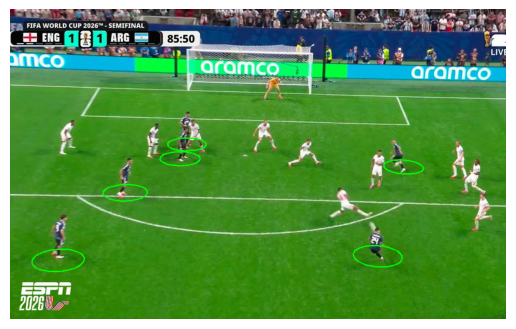

In [285]:
def proyectar(H, x, y):
    q = H @ np.array([x, y, 1.0])
    return q[0] / q[2], q[1] / q[2]       # (u, v) en píxeles

H_inv = inversa(H)

img = cv2.imread("futbol/test-gol-enzo.png")
assert img is not None, "no se encontró la imagen"

def dibujar_circulo(img, H, cx, cy, color=(0, 255, 0), grosor=2):
    t = np.linspace(0,2*np.pi, 60)
    pts = [proyectar(H,cx+1*np.cos(a),cy+1*np.sin(a))for a in t]
    pts = np.array(pts,dtype=np.int32)
    cv2.polylines(img,[pts],True,color,grosor)

for pos in posJugadores:
    U,V = proyectar(H_inv,pos[0],pos[1])
    dibujar_circulo(img,H,U,V)


plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Ejercicio c

Para construir H necesitamos elegir al menos 4 puntos, de forma que ninguna de las filas de la matriz sea linealmente dependiente de las demás. 

Elegimos 9 puntos con una separacion considerable entre sí. Los puntos reales de la cancha se eligieron tomando como referencia los datos del Estadio Azteca, y los puntos de la imagen los seleccionamos utilizando Paint, poniendo el cursor sobre el pixel buscado y registrando su valor.

En coordenadas reales, el area grande del lado derecho está en x=88,5; el area grande en x=99,5.
Desde el medio de la cancha (respecto a y), el arco tiene 3,66 mts para cada lado; 9,16 el área chica; y 20,16 el área grande.
La linea lateral superior está en y=0; la linea de fondo derecha en x=105.

In [286]:
puntos_cancha = np.array([
    [105,0],
    [105,(68/2)-(40.32/2)],
    [105,(68/2)-(18.32/2)],
    [105,(68/2)-(7.32/2)],
    [105-5.5,(68/2)-(18.32/2)],
    [105-5.5,(68/2)+(18.32/2)],
    [105-16.5,(68/2)-(40.32/2)],
    [105-16.5,(68/2)+(40.32/2)],

])

puntos_imagen = np.array([
    [1306, 235],
    [1388, 311],
    [1475, 387],
    [1524, 433],
    [1231, 391],
    [1365, 575],
    [735, 317],
    [736, 755],
])

Para obtener la matriz H, se debe descomponer Q en SVD, y tomar la última columna de V (o última fila de V traspuesta), que será igual a la matriz h (los elementos de la matriz H puestos como vector)

In [287]:
Q = obtenerQ2d(puntos_imagen,puntos_cancha)
H = resolver2D(Q)
H

[[ 7.9565000000e+04  2.0031100000e+04  7.9600000000e+02  0.0000000000e+00
   0.0000000000e+00  0.0000000000e+00 -9.9987613750e+07 -2.4051564840e+07
  -9.8625050000e+05]
 [ 2.0031100000e+04  7.3337492000e+03  2.0502000000e+02  0.0000000000e+00
   0.0000000000e+00  0.0000000000e+00 -2.4051564840e+07 -8.1808036224e+06
  -2.4161268000e+05]
 [ 7.9600000000e+02  2.0502000000e+02  8.0000000000e+00  0.0000000000e+00
   0.0000000000e+00  0.0000000000e+00 -9.8625050000e+05 -2.4161268000e+05
  -9.7600000000e+03]
 [ 0.0000000000e+00  0.0000000000e+00  0.0000000000e+00  7.9565000000e+04
   2.0031100000e+04  7.9600000000e+02 -3.3019963500e+07 -1.0283516060e+07
  -3.3441900000e+05]
 [ 0.0000000000e+00  0.0000000000e+00  0.0000000000e+00  2.0031100000e+04
   7.3337492000e+03  2.0502000000e+02 -1.0283516060e+07 -4.2846672564e+06
  -1.0686206000e+05]
 [ 0.0000000000e+00  0.0000000000e+00  0.0000000000e+00  7.9600000000e+02
   2.0502000000e+02  8.0000000000e+00 -3.3441900000e+05 -1.0686206000e+05
  -3.40

array([[-0.0146887183,  0.0027879053,  0.9941238917],
       [ 0.0000787237, -0.001082335 , -0.1072045723],
       [-0.0000001971,  0.0000038074, -0.0003988915]])

Verificamos que esté bien calculada con algunos puntos:

In [288]:
puntos_cancha_aux = []

for punto in puntos_cancha:
    punto = np.append(punto, 1)
    puntos_cancha_aux.append(punto)

puntos_cancha_aux = np.array(puntos_cancha_aux)

for punto in puntos_cancha_aux:
    print (calcularAx(H,punto))

[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.0000001971  0.0000038074 -0.0003988915]]
[-0.5481915284 -0.0989385883 -0.0004195877]
[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.0000001971  0.0000038074 -0.0003988915]]
[-0.5096069191 -0.1139181049 -0.0003668928]
[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.0000001971  0.0000038074 -0.0003988915]]
[-0.4789399608 -0.12582379   -0.0003250111]
[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.0000001971  0.0000038074 -0.0003988915]]
[-0.4636064816 -0.1317766326 -0.0003040702]
[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.0000001971  0.0000038074 -0.0003988915]]
[-0.3981520102 -0.1262567701 -0.000323927 ]
[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.00000

In [289]:
# Como queremos que la ultima coord del punto de la imagen sea 1, dividimos por ese valor
for punto in puntos_cancha_aux:
    punto_im = calcularAx(H,punto)
    punto_im = punto_im / punto_im[-1]
    print (punto_im)

[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.0000001971  0.0000038074 -0.0003988915]]
[1306.500493764   235.7995477921    1.          ]
[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.0000001971  0.0000038074 -0.0003988915]]
[1388.9803401155  310.494230234     1.          ]
[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.0000001971  0.0000038074 -0.0003988915]]
[1473.6112549436  387.1369446362    1.          ]
[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.0000001971  0.0000038074 -0.0003988915]]
[1524.6693281297  433.3757136378    1.          ]
[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.0000001971  0.0000038074 -0.0003988915]]
[1229.1412595241  389.7692375377    1.          ]
[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082

Los pixeles obtenidos son bastante cercanos a los de la imagen.

El pie del penúltimo jugador del otro equipo está en el pixel (827,327) aproximadamente. Lo pasamos a Coordenadas del mundo real con la inversa de H, y tomamos el punto que está a altura 0 con el mismo valor de x, y entre ellos trazamos la linea

In [290]:
inv_H = inversa(H)
pixel_pie = [827,327,1]
posicion_pie = calcularAx(inv_H,pixel_pie)
print(posicion_pie)

# Como queremos que la ultima coord del punto de la imagen sea 1, dividimos por ese valor
posicion_pie = posicion_pie / posicion_pie[-1]
print(posicion_pie)

[[   -69.3862239366   -404.5601445041 -64197.4268826453]
 [    -4.3398347625   -500.2262233172 123623.1135120758]
 [    -0.0071375893     -4.5747684887  -1295.2384127433]]
[-253871.0013311054  -43539.9048612706   -2797.090494896 ]
[90.7625269166 15.5661409385  1.          ]


El pie está en x = 90,76. 
Para trazar una recta paralela a la linea de fondo, buscamos el pixel correspondiente a la posición del mundo real (90.76,0), que es la posicion correspondiente al mismo valor de x sobre la linea lateral superior. Usamos la homografía para encontrar este valor.

In [291]:
segundo_punto = calcularAx(H,[90.76,0,1])
print(segundo_punto)
segundo_punto = segundo_punto / segundo_punto[-1]
print(segundo_punto)

[[-0.0146887183  0.0027879053  0.9941238917]
 [ 0.0000787237 -0.001082335  -0.1072045723]
 [-0.0000001971  0.0000038074 -0.0003988915]]
[-0.33902418   -0.1000596132 -0.0004167809]
[813.4350391039 240.0772575574   1.          ]


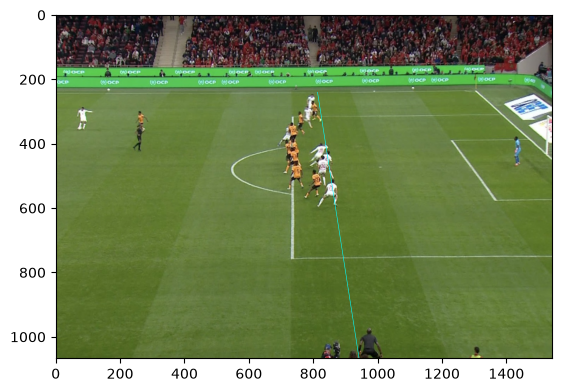

In [292]:
u1, v1, _ = pixel_pie
u2, v2, _ = segundo_punto

fuera_de_juego = cv2.imread('futbol/test-fuera-de-juego.png')
fuera_de_juego = cv2.cvtColor(fuera_de_juego, cv2.COLOR_BGR2RGB)
plt.imshow(fuera_de_juego)

m = (v2 - v1) / (u2 - u1)
b = v1 - m * u1
alto_img, ancho_img = fuera_de_juego.shape[0], fuera_de_juego.shape[1]

v_fin = alto_img - 1
u_fin = u2 + (v_fin - v2) / m

plt.plot([u2, u_fin], [v2, v_fin], color="cyan", linewidth=0.4)

plt.xlim(0, ancho_img)
plt.ylim(alto_img, 0)  

plt.show()

## Ejercicio 5 (Cálculo de velocidad real)
### a)

In [293]:
df = pd.read_csv('salguero/world_img_pts.csv', sep=";")
display(df)
display(df.shape)
data = df.values
display(data)

,pts,X,Y,Z,u_0,v_0,u_1,v_1,u_2,v_2,u_3,v_3
0,6,-4.0,3,0.0,281,474,255,490,469,581,446,563
1,36,4.0,0,0.0,889,521,1071,577,1147,653,1118,621
2,40,6.5,3,0.1,1139,493,1403,550,1425,625,1396,590
3,41,-5.0,14,0.1,418,385,437,377,627,485,600,466
4,42,-5.0,76,0.1,833,262,997,227,1094,357,1064,331


(5, 12)

array([[   6. ,   -4. ,    3. ,    0. ,  281. ,  474. ,  255. ,  490. ,
         469. ,  581. ,  446. ,  563. ],
       [  36. ,    4. ,    0. ,    0. ,  889. ,  521. , 1071. ,  577. ,
        1147. ,  653. , 1118. ,  621. ],
       [  40. ,    6.5,    3. ,    0.1, 1139. ,  493. , 1403. ,  550. ,
        1425. ,  625. , 1396. ,  590. ],
       [  41. ,   -5. ,   14. ,    0.1,  418. ,  385. ,  437. ,  377. ,
         627. ,  485. ,  600. ,  466. ],
       [  42. ,   -5. ,   76. ,    0.1,  833. ,  262. ,  997. ,  227. ,
        1094. ,  357. , 1064. ,  331. ]])

Como tenemos únicamente 5 puntos para realizar la calibración, no se puede realizar la de puntos 3D: Vamos a pensar el problema como uno de puntos coplanares. De esta forma se van a tener más que 4 puntos, que es lo necesario para realizar este tipo de calibración.

Al tener varias tomas distintas, podemos aprovechar esta información para calcular distintos Hj para armar la matriz A, y con ella la matriz K. Habiendo obtenido la matriz K, y para una vista Hj determinada, podemos calcular el valor de la pose de la cámara (los parámetros Rj y tj).

In [294]:
XY = data[:, 1:3]
u = data[:, 4:12:2]
v = data[:, 5:12:2]

In [295]:
lista_H = []
for i in range(4):
    ui = u[:,i]
    vi = v[:,i]

    objPts = XY
    imgPts = np.column_stack((ui, vi))

    Q = obtenerQ2d(imgPts, objPts)
    Hj = resolver2D(Q)
    lista_H.append(Hj)

A = armarA(lista_H)
K = calcularMatrizK2D(A).T
print(K)

[[ 1.242500000e+02 -4.425000000e+02 -3.500000000e+00  0.000000000e+00
   0.000000000e+00  0.000000000e+00 -9.811775000e+04  3.269615000e+05
  -3.580500000e+03]
 [-4.425000000e+02  5.990000000e+03  9.600000000e+01  0.000000000e+00
   0.000000000e+00  0.000000000e+00  3.269615000e+05 -4.906116000e+06
  -7.342000000e+04]
 [-3.500000000e+00  9.600000000e+01  5.000000000e+00  0.000000000e+00
   0.000000000e+00  0.000000000e+00 -3.580500000e+03 -7.342000000e+04
  -3.560000000e+03]
 [ 0.000000000e+00  0.000000000e+00  0.000000000e+00  1.242500000e+02
  -4.425000000e+02 -3.500000000e+00 -5.292425000e+04  1.225845000e+05
  -1.575000000e+02]
 [ 0.000000000e+00  0.000000000e+00  0.000000000e+00 -4.425000000e+02
   5.990000000e+03  9.600000000e+01  1.225845000e+05 -1.597475000e+06
  -2.820300000e+04]
 [ 0.000000000e+00  0.000000000e+00  0.000000000e+00 -3.500000000e+00
   9.600000000e+01  5.000000000e+00 -1.575000000e+02 -2.820300000e+04
  -2.135000000e+03]
 [-9.811775000e+04  3.269615000e+05 -3.5

# Los autovalores de una matriz usada en el cálculo de K son negativos, asi que al tomar raiz surge un error

### b)

In [296]:
np.set_printoptions(suppress=True, precision=2)
puntos_primera_imagen = np.loadtxt('salguero/gs_10_09_point_correspondences_v5.txt',delimiter='	')
puntos_primera_imagen

array([[  49.  ,   48.  ,   35.  ,    0.  ,    1.  ,    2.  ,    3.  ,
           4.  ,    5.  ,    6.  ,    7.  ,    8.  ,    9.  ,   10.  ,
          11.  ,   12.  ,   13.  ,   14.  ,   15.  ,   16.  ,   17.  ,
          18.  ,   19.  ,   20.  ,   21.  ,   22.  ,   23.  ,   24.  ,
          25.  ,   26.  ,   27.  ,   28.  ,   29.  ,   30.  ,   31.  ,
          32.  ,   33.  ,   34.  ,   36.  ,   37.  ,   38.  ,   39.  ,
          40.  ,   41.  ,   42.  ,   43.  ,   44.  ,   45.  ,   46.  ,
          47.  ,   50.  ],
       [   9.  ,   -6.  ,    5.  ,   -4.  ,   -3.5 ,   -4.  ,   -3.5 ,
          -3.  ,   -2.5 ,   -3.  ,   -2.5 ,   -2.  ,   -1.5 ,   -2.  ,
          -1.5 ,   -1.  ,   -0.5 ,   -1.  ,   -0.5 ,    0.  ,    0.5 ,
           0.  ,    0.5 ,    1.  ,    1.7 ,    1.  ,    1.7 ,    2.2 ,
           2.7 ,    2.2 ,    2.7 ,    3.3 ,    3.8 ,    3.3 ,    3.8 ,
           4.5 ,    5.  ,    4.5 ,    9.  ,    9.  ,    8.95,    8.95,
           8.9 ,    8.9 ,    8.85,    8.85,    8.8

En este caso todos los z valen 0, asi que nuevamente se usa el modelo de puntos coplanares.

In [297]:
XY, uv = (
    puntos_primera_imagen[1:3,:],
    puntos_primera_imagen[4:,:],

)

XY = XY.T
uv = uv.T
print(XY)
print(XY.shape)
print('\n')
print(uv)
print(uv.shape)

[[  9.    21.  ]
 [ -6.    76.  ]
 [  5.     3.  ]
 [ -4.     0.  ]
 [ -3.5    0.  ]
 [ -4.     3.  ]
 [ -3.5    3.  ]
 [ -3.     0.  ]
 [ -2.5    0.  ]
 [ -3.     3.  ]
 [ -2.5    3.  ]
 [ -2.     0.  ]
 [ -1.5    0.  ]
 [ -2.     3.  ]
 [ -1.5    3.  ]
 [ -1.     0.  ]
 [ -0.5    0.  ]
 [ -1.     3.  ]
 [ -0.5    3.  ]
 [  0.     0.  ]
 [  0.5    0.  ]
 [  0.     3.  ]
 [  0.5    3.  ]
 [  1.     0.  ]
 [  1.7    0.  ]
 [  1.     3.  ]
 [  1.7    3.  ]
 [  2.2    0.  ]
 [  2.7    0.  ]
 [  2.2    3.  ]
 [  2.7    3.  ]
 [  3.3    0.  ]
 [  3.8    0.  ]
 [  3.3    3.  ]
 [  3.8    3.  ]
 [  4.5    0.  ]
 [  5.     0.  ]
 [  4.5    3.  ]
 [  9.    -8.  ]
 [  9.    -8.5 ]
 [  8.95  -9.  ]
 [  8.95  -9.5 ]
 [  8.9  -10.  ]
 [  8.9  -10.5 ]
 [  8.85 -11.  ]
 [  8.85 -11.5 ]
 [  8.8  -12.1 ]
 [  8.8  -12.65]
 [  7.2    2.8 ]
 [ -6.    14.  ]
 [  9.    34.  ]]
(51, 2)


[[1214.  365.]
 [ 833.  262.]
 [ 959.  486.]
 [ 184.  505.]
 [ 223.  506.]
 [ 280.  474.]
 [ 319.  474.]
 [ 263.  505.]
 [

Calculamos la matriz Hj específica para esta toma, y se aprovecha el calculo de los parámetros intrínsecos (K) en el item anterior para estimar Rj y tj.

In [298]:
Q = obtenerQ2d(uv,XY)
Hj = resolver2D(Q)
Rj,tj = obtenerPose2D(Hj, K)
Rj,tj

[[ 1.35e+03 -9.18e+02  1.16e+02  0.00e+00  0.00e+00  0.00e+00 -1.65e+06
   1.12e+06 -1.84e+05]
 [-9.18e+02  8.82e+03  9.90e+01  0.00e+00  0.00e+00  0.00e+00  1.12e+06
  -8.52e+06 -1.82e+04]
 [ 1.16e+02  9.90e+01  5.10e+01  0.00e+00  0.00e+00  0.00e+00 -1.84e+05
  -1.82e+04 -4.05e+04]
 [ 0.00e+00  0.00e+00  0.00e+00  1.35e+03 -9.18e+02  1.16e+02 -9.11e+05
   7.50e+05 -8.82e+04]
 [ 0.00e+00  0.00e+00  0.00e+00 -9.18e+02  8.82e+03  9.90e+01  7.50e+05
  -3.14e+06  1.75e+04]
 [ 0.00e+00  0.00e+00  0.00e+00  1.16e+02  9.90e+01  5.10e+01 -8.82e+04
   1.75e+04 -2.80e+04]
 [-1.65e+06  1.12e+06 -1.84e+05 -9.11e+05  7.50e+05 -8.82e+04  2.90e+09
  -2.24e+09  3.28e+08]
 [ 1.12e+06 -8.52e+06 -1.82e+04  7.50e+05 -3.14e+06  1.75e+04 -2.24e+09
   1.03e+10 -1.18e+08]
 [-1.84e+05 -1.82e+04 -4.05e+04 -8.82e+04  1.75e+04 -2.80e+04  3.28e+08
  -1.18e+08  5.77e+07]]
[[ 1.35e+03 -9.18e+02  1.16e+02  0.00e+00  0.00e+00  0.00e+00 -1.65e+06
   1.12e+06 -1.84e+05]
 [-9.18e+02  8.82e+03  9.90e+01  0.00e+00  0.00e+

(array([[-0.  , -0.  ,  0.  ],
        [ 0.  ,  0.  ,  0.  ],
        [-1.  , -0.55,  0.  ]]),
 array([-0.  ,  0.  , -5.08]))

# No entiendo a que se refiere con reproyectar

### c)

Tenemos 46 tomas, y todas tienen la misma posición de la cámara, y comparten el parámetro intrínseco. Elegimos tratarla como se fuera una única imagen que tiene distintos puntos. 

El segundo final es el 52.546, y el inicial el 47,351. El lapso es de 5,195 segundos. Vamos a usar 6 tomas distribuidas de forma uniforme entre la primera y la ultima para tener un frame cada un segundo aproximadamente, ya que se asume que la separación temporal entre una toma y la siguiente es similar para todas.

Se eligen las imágenes 1,10,19,28,37,46.

Im1: img_10_18_47_351.jpg

Im10: img_10_18_48_350.jpg

Im19: img_10_18_49_582.jpg

Im28: img_10_18_50_534.jpg

Im37: img_10_18_51_563.jpg

Im46: img_10_18_52_546.jpg


In [299]:
señora_px = np.array([[418,501],[544,495],[695,490],[814,490],[909,489],[989,489]])
taxi_px = np.array([[933,267],[900,283],[835,307],[756,350],[612,419],[299,577]])
camioneta_px = np.array([[995,258],[988,270],[972,288],[941,317],[891,361],[788,445]])
segundos = np.array([47.351,48.350,49.582,50.534,51.563,52.546])

Nuevamente los u,v se seleccionaron mediante Paint.

En el b se calculó la pose de la cámara para la imagen img_10_18_47_351.jpg, que es la misma que la primera de estas 6. Por lo tanto ya se tiene K,Rj y tj para esa imagen y las otras 5.

Se utiliza esta información para construir H, y pasar de las coordenadas en pantalla a las coordenadas reales, así calculamos las velocidades.
Las mismas serán entre los intervalos 1-10, 10-19, 19-28, 28-37, 37-46. Cada una se va a calcular como la norma 2 de (xf,yf)-(xi,yf) (la variación de la distancia), y dividimos por el segundo final menos el segundo inicial. Vamos a tomar la velocidad que se pide en la consigna como el promedio de estas 5 velocidades.

In [300]:
np.set_printoptions(suppress=True, precision=10)

def obtener_velocidad(puntos_px, H, segs):
    inv_H = inversa(H)
    # Pasamos de puntos de la imagen a puntos reales, y agregamos 1 al final
    puntos_reales = np.array([calcularAx(inv_H, np.append(punto, 1)) for punto in puntos_px])
    puntos_reales = puntos_reales / puntos_reales[:,2:3]

    # Calculamos el vector desplazamiento entre un punto y el siguiente, para todos los puntos
    desplazamientos = np.diff(puntos_reales, axis=0)

    # Pasamos los vectores desplazamiento a un número a traves de la norma
    metros_recorridos = norma(desplazamientos.T, 2)

    # Calculamos la variación de tiempo entre una imagen y la otra, para todas las imagenes
    variaciones_tiempo = np.diff(segs)

    # Calculamos la velocidad como la distancia recorrida entre el tiempo transcurrido
    velocidades = metros_recorridos / variaciones_tiempo

    # Calculamos la velocidad promedio como la suma de todas las velocidades dividido la cantidad de muestras
    promedio_velocidad = sum(velocidades) / len(velocidades)

    return promedio_velocidad

velocidad_promedio_señora = obtener_velocidad(señora_px, Hj, segundos)
velocidad_promedio_taxi = obtener_velocidad(taxi_px, Hj, segundos)
velocidad_promedio_camioneta = obtener_velocidad(camioneta_px, Hj, segundos)

print(velocidad_promedio_señora,velocidad_promedio_taxi,velocidad_promedio_camioneta)

[[    -8.3023014973    -14.7711527944  11815.6790979068]
 [    -1.4364582968     50.5106646386 -25080.4221088458]
 [     0.0045764153     -2.218971112     401.2134974038]]
[[    -8.3023014973    -14.7711527944  11815.6790979068]
 [    -1.4364582968     50.5106646386 -25080.4221088458]
 [     0.0045764153     -2.218971112     401.2134974038]]
[[    -8.3023014973    -14.7711527944  11815.6790979068]
 [    -1.4364582968     50.5106646386 -25080.4221088458]
 [     0.0045764153     -2.218971112     401.2134974038]]
[[    -8.3023014973    -14.7711527944  11815.6790979068]
 [    -1.4364582968     50.5106646386 -25080.4221088458]
 [     0.0045764153     -2.218971112     401.2134974038]]
[[    -8.3023014973    -14.7711527944  11815.6790979068]
 [    -1.4364582968     50.5106646386 -25080.4221088458]
 [     0.0045764153     -2.218971112     401.2134974038]]
[[    -8.3023014973    -14.7711527944  11815.6790979068]
 [    -1.4364582968     50.5106646386 -25080.4221088458]
 [     0.0045764153     -2

# En realidad no calculamos Hj nuevamente con K,Rj y tj, sino que usamos la matriz Hj que ya obtuvimos en el b. No entiendo de que sirve calcular la pose en ese ejercicio. Me dio que se mueven a mas de 900 m/s, hay un error claro en alguna funcion auxiliar o en los datos tomados

# Ejercicio 6
## a

label;U [m];V [m];W [m]

centro de la H (M0);0.000;0.0;0.0

extremo exterior sup. izq. de H;-0.175;0.3;0.0

extremo exterior sup. der. de H;0.175;0.3;0.0

extremo exterior inf. der. de H;0.175;-0.3;0.0

extremo exterior inf. izq. de H;-0.175;-0.3;0.0

In [301]:
centro_real = 0.0,0.0
sup_izq_real = -0.175,0.3
sup_der_real = 0.175,0.3
inf_der_real = 0.175,-0.3
inf_izq_real = -0.175,-0.3
UVW = np.array([centro_real,sup_izq_real,sup_der_real,inf_der_real,inf_izq_real])

centro_px = 526,1007
sup_izq_px = 402,1097
sup_der_px = 392,944
inf_der_px = 644,913
inf_izq_px = 656,1061
uv = np.array([centro_px,sup_izq_px,sup_der_px,inf_der_px,inf_izq_px])

display(UVW)
display(uv)

array([[ 0.   ,  0.   ],
       [-0.175,  0.3  ],
       [ 0.175,  0.3  ],
       [ 0.175, -0.3  ],
       [-0.175, -0.3  ]])

array([[ 526, 1007],
       [ 402, 1097],
       [ 392,  944],
       [ 644,  913],
       [ 656, 1061]])

In [302]:
Q = obtenerQ2d(uv, UVW)
H = resolver2D(Q)
K = np.loadtxt("heli/K.csv", delimiter=";")
R,t = obtenerPose2D(H, K)
np.set_printoptions(suppress=True, precision=8)
print(R,t)

[[      0.1225             0.                 0.
        0.                 0.                 0.
      -64.12875           -0.105              3.85        ]
 [      0.                 0.36               0.
        0.                 0.                 0.
       -0.105           -188.46             151.8         ]
 [      0.                 0.                 5.
        0.                 0.                 0.
        3.85             151.8            -2620.          ]
 [      0.                 0.                 0.
        0.1225             0.                 0.
     -122.959375           0.2625            52.675       ]
 [      0.                 0.                 0.
        0.                 0.36               0.
        0.2625          -361.35             -20.1         ]
 [      0.                 0.                 0.
        0.                 0.                 5.
       52.675            -20.1            -5022.          ]
 [    -64.12875           -0.105              3.85
 

# No se si el resultado es correcto

## b

In [303]:
def calculoLambdaMu(I0,J0):
    a = norma(J0,2)**2 - norma(I0,2)**2
    b = -2*multiplicarMatrices(I0.T,J0)
    r = np.sqrt(a**2+b**2)
    lamb = np.sqrt((r+a)/2)
    
    mu  = np.sqrt((r-a)/2)
    if b < 0:
        mu = -mu
    return lamb, mu




## c

In [304]:
def calcularSalidaPOSIT(Is, Js, fx, m0, M0):
    Z0 = fx / norma(Is,2)
    i = Is / norma(Is,2)
    j = Js / norma(Js,2)

    k = np.array([
    i[1]*j[2] - i[2]*j[1],
    i[2]*j[0] - i[0]*j[2],
    i[0]*j[1] - i[1]*j[0]
    ])

    R = np.array([i,j,k])

    x0 = m0[0]
    y0 = m0[1]

    X0 = (Z0 / fx)*x0 
    Y0 = (Z0/fx)*y0

    T = np.array([X0,Y0,Z0])
    
    t = T - multiplicarMatrices(R,M0).reshape(3)

    return i, j, k, Z0, R, T

# Gracias a ChatGPT, es un capo, no como los profes de labo de ALC